# Customer Segmentation using K-Means Clustering

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## 2. Load the dataset
This file is not UTF-8, so `encoding="latin1"` is needed.

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


## 3. Check the data

In [3]:
df.shape

(2823, 25)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

## 4. Select numeric columns for clustering

In [5]:
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]]
X.head()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP
0,30,95.70,2871.00,95
1,34,81.35,2765.90,95
2,41,94.74,3884.34,95
3,45,83.26,3746.70,95
4,49,100.00,5205.27,95


## 5. Scaling

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 6. Elbow method to find the best number of clusters

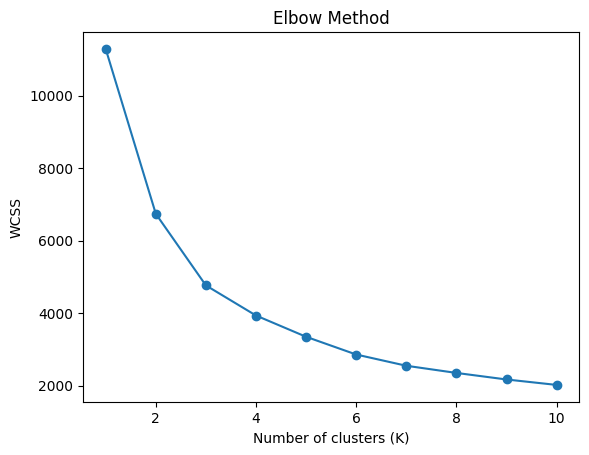

In [7]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.show()

## 7. Apply K-Means with the best K
Read the elbow (the point where the curve stops dropping sharply) from the graph above. Change `n_clusters` if your elbow is at a different K.

In [8]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)
df[["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP", "Cluster"]].head()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP,Cluster
0,30,95.70,2871.00,95,2
1,34,81.35,2765.90,95,2
2,41,94.74,3884.34,95,1
3,45,83.26,3746.70,95,1
4,49,100.00,5205.27,95,1


## 8. Number of customers in each cluster

In [9]:
df["Cluster"].value_counts()

Cluster
2    996
0    975
1    852
Name: count, dtype: int64

## 9. Average values of each cluster

In [10]:
df.groupby("Cluster")[["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]].mean()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP
Cluster,,,,
0,35.208205,59.551169,2101.076482,64.145641
1,43.723005,97.479261,5720.080669,127.893192
2,27.597390,95.435090,3123.062801,113.266064


## 10. Visualize the clusters

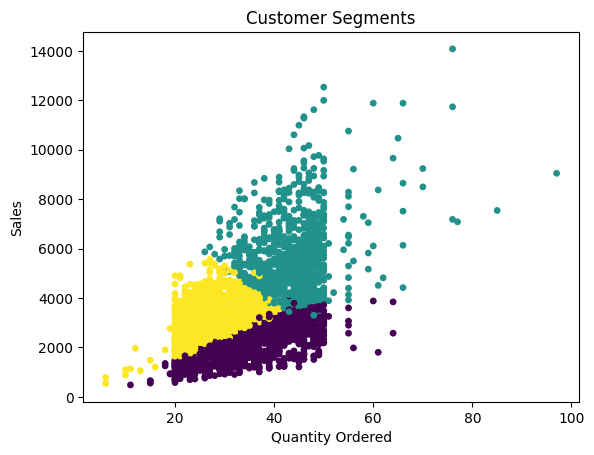

In [11]:
plt.scatter(df["QUANTITYORDERED"], df["SALES"], c=df["Cluster"], cmap="viridis", s=15)
plt.title("Customer Segments")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

## Conclusion
The elbow method showed that 3 clusters is a good choice. K-Means grouped the orders into 3 segments, such as low, medium and high sales customers.